In [ ]:
import requests                           #
from bs4 import BeautifulSoup             #
import pandas as pd                      #
import matplotlib.pyplot as plt
from wordcloud import WordCloud

import time                          # Time and Collections are used to set a counter for the number of times a word appears in the text
from collections import Counter

In [12]:
BASE_URL = "https://wheeloffortuneanswer.com/"
headers = {"User-Agent": "StudentScraper/1.0"}

#Developers have mecahnisms to prevent scraping. These strategies prevent people from scraping their websites. 
# One of the strategies is to block requests that do not have a user-agent header. The user-agent header is a string that identifies the browser and operating system of the client making the request. 
# By including a user-agent header in your requests, you can make it look like your requests are coming from a real browser, which can help you avoid being blocked by the website.

In [13]:
print(requests.get(BASE_URL + "robots.txt", timeout=15, headers=headers).text[:200])

#****************************************************************************
# robots.txt
#     : Robots, spiders, and search engines use this file to detmine which 
#       content they should *not*


In [ ]:
#Downloading home page
response = requests.get(BASE_URL, headers=headers)
response 

<Response [200]>

In [15]:
## <table> </table> = the table
## <thead> </thead> = the header of the table
## <tr> </tr> = the row of the table
## <td> </td> = the data cell of the table
## <a href="url"> </a> = the link of the table

In [16]:
response.text[:300]

'<!DOCTYPE html>\n<!--[if IE 8]>\t<html class="ie8" lang="en-US"> <![endif]-->\n<!--[if IE 9]>\t<html class="ie9" lang="en-US"> <![endif]-->\n<!--[if !(IE 8) | !(IE 9) ]><!-->\t<html lang="en-US"> <!--<![endif]-->\n<head>\n<meta charset="UTF-8" />\n<meta name=\'viewport\' content=\'width=device-width,initial-sca'

In [17]:
print(response.text)

<!DOCTYPE html>
<!--[if IE 8]>	<html class="ie8" lang="en-US"> <![endif]-->
<!--[if IE 9]>	<html class="ie9" lang="en-US"> <![endif]-->
<!--[if !(IE 8) | !(IE 9) ]><!-->	<html lang="en-US"> <!--<![endif]-->
<head>
<meta charset="UTF-8" />
<meta name='viewport' content='width=device-width,initial-scale=1.0' />

<link rel="profile" href="//gmpg.org/xfn/11" />



<link href='https://fonts.googleapis.com/css?family=Open+Sans:400%2C700%2C700italic%2C400italic%7COpen+Sans+Condensed:300%2C700%7CAlegreya:400%2C400italic%2C700%2C700italic%7CAlegreya+Sans:400%2C400italic%2C700%2C700italic%7CDroid+Sans:400%2C700%7CDroid+Serif:400%2C400italic%2C700%2C700italic%7CExo+2:400%2C700%7CLato:400%2C400italic%2C700%2C700italic%7CLora:400%2C400italic%2C700%2C700italic%7CArvo:400%2C700%2C400italic%2C700italic%7CRoboto:400%2C400italic%2C700%2C700italic%7CRoboto+Condensed:400%2C700%7CRoboto+Slab:400%2C700%7CArchivo+Black%7CSource+Sans+Pro:400%2C400italic%2C700%2C700italic%7CSource+Serif+Pro:400%2C700%7CVollkor

In [18]:
## Picking the table from the website
soup = BeautifulSoup(response.text, 'html.parser')

In [19]:
table = soup.find('table')

In [20]:
rows = table.find_all("tr")
rows

[<tr class="row-1">
 <th class="column-1">Category<br/>
 (Full Answer)</th><th class="column-2">Filter<br/>
 (Beta)</th>
 </tr>,
 <tr class="row-2">
 <td class="column-1"><a href="https://wheeloffortuneanswer.com/around-the-house/">Around the House</a></td><td class="column-2"><a href="https://wheeloffortuneanswer.com/filter/?category=Around%20the%20House.">Around the House Filter</a></td>
 </tr>,
 <tr class="row-3">
 <td class="column-1"><a href="https://wheeloffortuneanswer.com/before-and-after/">Before and After</a></td><td class="column-2"><a href="https://wheeloffortuneanswer.com/filter/?category=Before%20and%20After.">Before and After Filter</a></td>
 </tr>,
 <tr class="row-4">
 <td class="column-1"><a href="https://wheeloffortuneanswer.com/book-title/">Book Title (Best Seller)</a></td><td class="column-2"><a href="https://wheeloffortuneanswer.com/filter/?category=Book%20Title.">Book Title (Best Seller) Filter</a></td>
 </tr>,
 <tr class="row-5">
 <td class="column-1"><a href="ht

In [21]:
##
rows[1].find_all("td")

[<td class="column-1"><a href="https://wheeloffortuneanswer.com/around-the-house/">Around the House</a></td>,
 <td class="column-2"><a href="https://wheeloffortuneanswer.com/filter/?category=Around%20the%20House.">Around the House Filter</a></td>]

In [22]:
## Note:Finding specific table can be done by using the id number.

## Extracting all the categories and their urls from the table
categories = []
for rows in table.find_all("tr"):
    cells = rows.find_all("td")
    if not cells: #eliminating table headers
        continue
    link = cells[0].find("a") # The zero can change based on which column you are specifying. In this case, the first column is the category name and the second column is the link to the category page.
    if link:
        categories.append({
            "category": link.get_text(strip=True), 
            "url": link["href"]})

categories

[{'category': 'Around the House',
  'url': 'https://wheeloffortuneanswer.com/around-the-house/'},
 {'category': 'Before and After',
  'url': 'https://wheeloffortuneanswer.com/before-and-after/'},
 {'category': 'Book Title (Best Seller)',
  'url': 'https://wheeloffortuneanswer.com/book-title/'},
 {'category': 'Classic Movie',
  'url': 'https://wheeloffortuneanswer.com/classic-movie/'},
 {'category': 'Classic TV',
  'url': 'https://wheeloffortuneanswer.com/classic-tv/'},
 {'category': 'College Life',
  'url': 'https://wheeloffortuneanswer.com/college-life/'},
 {'category': 'Event', 'url': 'https://wheeloffortuneanswer.com/event/'},
 {'category': 'Family', 'url': 'https://wheeloffortuneanswer.com/family/'},
 {'category': 'Fictional Character',
  'url': 'https://wheeloffortuneanswer.com/fictional-character/'},
 {'category': 'Fictional Place',
  'url': 'https://wheeloffortuneanswer.com/fictional-place/'},
 {'category': 'Food and Drink',
  'url': 'https://wheeloffortuneanswer.com/food-and-dr

In [23]:
categories_df = pd.DataFrame(categories)
print(f"Total categories found: {categories_df.shape[0]}")
categories_df.head(7)

Total categories found: 50


,category,url
0,Around the House,https://wheeloffortuneanswer.com/around-the-ho...
1,Before and After,https://wheeloffortuneanswer.com/before-and-af...
2,Book Title (Best Seller),https://wheeloffortuneanswer.com/book-title/
3,Classic Movie,https://wheeloffortuneanswer.com/classic-movie/
4,Classic TV,https://wheeloffortuneanswer.com/classic-tv/
5,College Life,https://wheeloffortuneanswer.com/college-life/
6,Event,https://wheeloffortuneanswer.com/event/


In [24]:
## Scrape answers from one category page
def scrape_category(url):
    page = requests.get(url, headers=headers)
    page.raise_for_status()
    soup = BeautifulSoup(page.text, 'html.parser')
    table = soup.find('table')

    rows = []
    for row in table.find_all("tr"):
        cells = [td.get_text(strip=True) for td in row.find_all("td")]
        if len(cells)>=4:
            rows.append(cells[:4])

    return pd.DataFrame(rows, columns=["answer", "word", "letters", "first word letters"])

    

In [25]:
print(f"Category list: {categories_df}")

Category list:                     category  \
0           Around the House   
1           Before and After   
2   Book Title (Best Seller)   
3              Classic Movie   
4                 Classic TV   
5               College Life   
6                      Event   
7                     Family   
8        Fictional Character   
9            Fictional Place   
10            Food and Drink   
11             Fun and Games   
12                  Headline   
13          Husband and Wife   
14            In the Kitchen   
15                  Landmark   
16              Living Thing   
17                  Megaword   
18              Movie Quotes   
19               Movie Title   
20                Occupation   
21                On the Map   
22                    People   
23                    Person   
24                    Phrase   
25                     Place   
26               Proper Name   
27                 Quotation   
28                Rhyme Time   
29                   Rock

In [26]:
occupation_url = categories_df.loc[categories_df['category'] == 'Occupation', 'url'].iloc[0]
print(f"URL: {occupation_url}")

URL: https://wheeloffortuneanswer.com/occupation/


In [27]:
answers_occupation = scrape_category(occupation_url)
answers_occupation.head(10)

,answer,word,letters,first word letters
0,Academic Advisor,2,15,8
1,Acclaimed Film Director,3,21,9
2,Accordionist,1,12,12
3,Account Executive,2,16,7
4,Activities Manager,2,17,10
5,Ad Exec,2,6,2
6,Ad Executive,2,11,2
7,Adjunct Professor,2,16,7
8,Administrator,1,13,13
9,Advertising Director,2,19,11


In [28]:
title_url = categories_df.loc[categories_df['category'] == 'Title', 'url'].iloc[0]
print(f"URL: {title_url}")

URL: https://wheeloffortuneanswer.com/title/


In [29]:
answers_title = scrape_category(title_url)
answers_title.head(10)

,answer,word,letters,first word letters
0,A Bend In The River,5,15,1
1,A Bronx Tale,3,10,1
2,A Bug's Life,3,9,1
3,A Case Of Need,4,11,1
4,A Certain Age,3,11,1
5,A Charlie Brown Thanksgiving,4,25,1
6,A Chorus Line,3,11,1
7,A Christmas Carol,3,15,1
8,A Clash Of Kings,4,13,1
9,A Clockwork Orange,3,16,1


In [30]:
## 1. The columns should be in their right data types.
for columns in ["word", "letters", "first word letters"]:
    answers_title[columns] = pd.to_numeric(answers_title[columns], errors='coerce')

answers_title.dtypes

answer                object
word                   int64
letters                int64
first word letters     int64
dtype: object

In [31]:
answers_title.to_csv("Title.csv", index=False)

In [32]:
## Removing stopwords
from wordcloud import STOPWORDS

## Removing stopwords

text = " ".join(answers_title["answer"].dropna().str.lower())
stopwords = set(STOPWORDS)

words = [w.strip(".,!?'\u201c\u201d&-") for w in text.split()]
words = [w for w in words if w and w not in stopwords and len(w) > 1]

print(f"Words after cleaning: {len(words)}")
print(Counter(words).most_common(10))



Words after cleaning: 2678
[('magazine', 22), ('little', 18), ('best', 13), ('girl', 12), ('book', 12), ('life', 11), ('blue', 11), ('time', 10), ('song', 9), ('man', 9)]


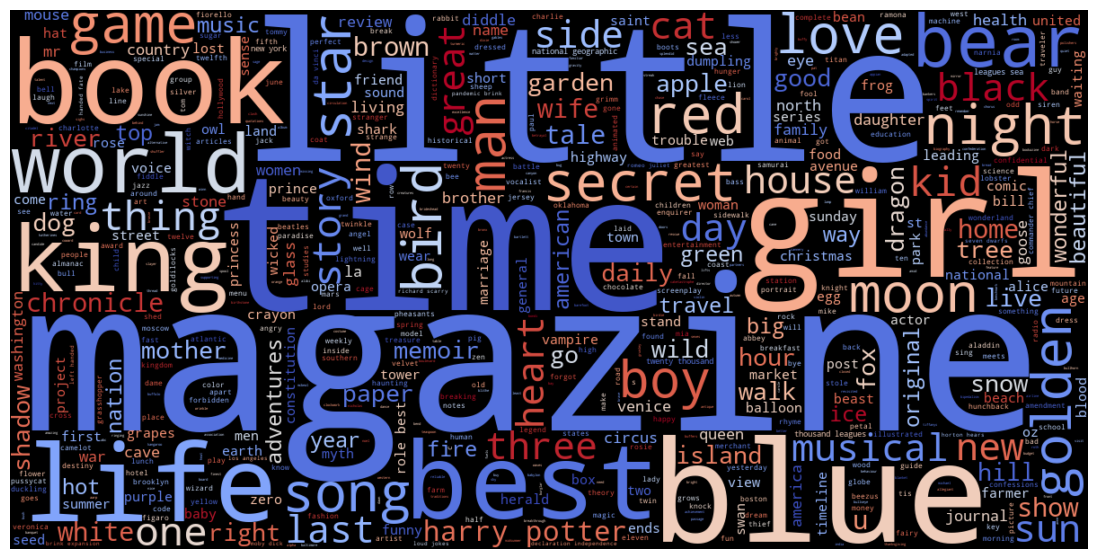

In [33]:
wc = WordCloud(width=1200, height=600, colormap="coolwarm", max_words=600, random_state=42).generate(" ".join(words))

plt.figure(figsize=(14, 7))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.show()